# 04b · Extensión Fase 3: entrenamiento controlado de ViT-B/16

Este notebook agrega un cuarto clasificador (**ViT-B/16**, `torchvision.models.vit_b_16`,
pesos oficiales `IMAGENET1K_V1` con interpolación bicúbica de embeddings posicionales
de 224 a 512 px) bajo el **mismo protocolo controlado** que ConvNeXt-Tiny, VMamba-Tiny
y el Híbrido de atención cruzada:

- Mismas tres clases (`health=0`, `sick=1`, `TB=2`) y particiones congeladas (`5.792 / 1.241 / 1.241`).
- Misma entrada RGB 512×512 con letterbox y normalización ImageNet (`configs/data.json`).
- Misma `seed=20261019`, hasta 12 épocas, 2 de warmup (`head_lr=3e-4`), ajuste de los últimos
  bloques (`backbone_lr=5e-6`), lote efectivo 32 (`batch_size=2`, `accumulation_steps=16`),
  FP32, paciencia 4, `min_delta=0.001` y selección por `validation_macro_f1`.
- **El conjunto de prueba (`test`) y externos permanecen reservados.**

Al finalizar, la última celda exporta las figuras (PNG 300 dpi, PDF, SVG), tablas CSV y
el resumen JSON en el formato exacto del informe de Fase 5 para actualizar
`Informe_Avance_Fase_5.docx`.

## Paso 1 — Montar Drive, verificar paquete ZIP y preparar dataset

Coloque `tbx11k_vit_entrenamiento_colab.zip` en `MyDrive/Proyecto_Tuberculosis/`
(junto a `TBX11K.zip` o `TBX11K/`). No sobrescribe los experimentos anteriores.

In [1]:
import hashlib, importlib.metadata as metadata, json, stat, subprocess, sys, zipfile
from pathlib import Path, PurePosixPath
from google.colab import drive
drive.mount('/content/drive')
DRIVE_BASE = Path('/content/drive/MyDrive/Proyecto_Tuberculosis')
ARCHIVE = DRIVE_BASE / 'tbx11k_vit_entrenamiento_colab.zip'
EXPECTED_PACKAGE_SHA256 = '1cecefafc27c0f3d16b2554aaecb59cd61443cc91bc5e49e94179c4cca08d25b'
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()
if file_sha256(ARCHIVE) != EXPECTED_PACKAGE_SHA256:
    raise ValueError('ZIP diferente de esta versión del notebook. Use ambos archivos de la misma entrega.')
PROJECT_ROOT = Path('/content/tbx11k_vit/project')
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ARCHIVE) as archive:
    names = archive.namelist()
    if len(names) != len(set(names)):
        raise ValueError('ZIP con nombres duplicados.')
    for item in archive.infolist():
        rel = PurePosixPath(item.filename)
        target = (PROJECT_ROOT / item.filename).resolve()
        if (rel.is_absolute() or '..' in rel.parts or ':' in item.filename
                or chr(92) in item.filename or stat.S_ISLNK(item.external_attr >> 16)
                or PROJECT_ROOT.resolve() not in target.parents):
            raise ValueError('Ruta ZIP insegura: ' + item.filename)
    checksums = json.loads(archive.read('vit_package_checksums.json'))
    if set(names) != set(checksums) | {'vit_package_checksums.json'}:
        raise ValueError('Cobertura de checksums incorrecta.')
    for name, expected in checksums.items():
        if hashlib.sha256(archive.read(name)).hexdigest() != expected:
            raise ValueError('Archivo alterado en el paquete: ' + name)
    archive.extractall(PROJECT_ROOT)
for name in list(sys.modules):
    if name in {'tbxdata', 'tbxtrain'} or name.startswith(('tbxdata.', 'tbxtrain.')):
        del sys.modules[name]
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
print('Paquete verificado y extraído en:', PROJECT_ROOT)

Mounted at /content/drive
Paquete verificado y extraído en: /content/tbx11k_vit/project


In [2]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError('Seleccione un runtime GPU de Colab (T4/L4/A100).')
protected = {}
for name in ['torch', 'torchvision', 'torchaudio']:
    try:
        protected[name] = metadata.version(name)
    except metadata.PackageNotFoundError:
        pass
constraints = PROJECT_ROOT / 'runtime_constraints.txt'
constraints.write_text(''.join(f'{k}=={v}\n' for k, v in protected.items()))
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '--quiet', '--disable-pip-version-check',
    '-c', str(constraints), '-r', str(PROJECT_ROOT / 'requirements-training.txt'),
])
if any(metadata.version(k) != v for k, v in protected.items()):
    raise RuntimeError('Se alteró torch/torchvision del runtime. Reinicie antes de continuar.')
from tbxdata.colab import stage_dataset
from tbxdata.validate import validate_manifests
from tbxtrain.vit_experiment import validate_vit_config
source = DRIVE_BASE / 'TBX11K.zip'
if not source.exists():
    source = DRIVE_BASE / 'TBX11K'
DATASET_ROOT = stage_dataset(source, Path('/content/tbx11k_vit/data_cache'), True)
integrity = validate_manifests(PROJECT_ROOT, DATASET_ROOT, all_image_hashes=True)
CONFIG_VIT = validate_vit_config(json.loads((PROJECT_ROOT / 'configs/vit_controlled.json').read_text()), PROJECT_ROOT)
print('GPU:', torch.cuda.get_device_name(0), '| torch:', torch.__version__, '| Integridad:', integrity['status'])
print('Hashes verificados:', integrity['all_image_hashes_verified'])
print(json.dumps(CONFIG_VIT, indent=2, ensure_ascii=False))

GPU: NVIDIA L4 | torch: 2.14.1+cu130 | Integridad: passed
Hashes verificados: 12278
{
  "protocol_id": "phase3_controlled_vit_v1",
  "architecture": "vit_b_16",
  "display_name": "ViT-B/16",
  "weights": "ViT_B_16_Weights.IMAGENET1K_V1",
  "seed": 20261019,
  "epochs": 12,
  "warmup_epochs": 2,
  "batch_size": 2,
  "accumulation_steps": 16,
  "num_workers": 2,
  "head_lr": 0.0003,
  "backbone_lr": 5e-06,
  "weight_decay": 0.01,
  "gradient_clip": 1.0,
  "patience": 4,
  "min_delta": 0.001,
  "precision": "fp32",
  "selection_metric": "validation_macro_f1",
  "initialization": "ImageNet oficial IMAGENET1K_V1 con interpolación bicúbica de embeddings posicionales 224->512",
  "scope": "Extensión de comparación controlada con una seed; mismos datos, splits, aumentos e hiperparámetros que phase3_controlled_v1"
}


## Paso 2 — Smoke técnico de ViT-B/16 (`RUN_SMOKES = True`)

Una imagen por clase (`health`, `sick`, `TB`) a 512 px verifica descarga oficial de pesos,
interpolación de embeddings posicionales, forward/backward, actualización de la cabeza y
reproducibilidad exacta al recargar `best.pt`. No aporta métricas de comparación.

In [3]:
from tbxtrain.vit_experiment import run_vit_model
RUN_SMOKES = True
if RUN_SMOKES:
    smoke = run_vit_model(PROJECT_ROOT, DATASET_ROOT, DRIVE_BASE, CONFIG_VIT, smoke=True)
    print('Smoke ViT-B/16:', smoke['status'], '| updates:', smoke['optimizer_updates'])

Corrida: smoke_vit_20261116T014730Z_b68b52 
Salidas: /content/drive/MyDrive/Proyecto_Tuberculosis/experiments/smoke_vit_20261116T014730Z_b68b52
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 127MB/s]
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:910.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


  época 1 lote 3/3 loss=1.2849
Época 1: macro-F1=0.5556, TB recall=1.0000; Drive guardado.
Smoke ViT-B/16: completed_smoke | updates: 2


## Paso 3 — Entrenamiento completo controlado de ViT-B/16 y recuperación automática

Guarda `last.pt` e `history.csv` al finalizar cada época en Drive. Si la sesión se
interrumpe, vuelva a ejecutar desde el Paso 1 (puede poner `RUN_SMOKES = False`) y esta
celda retomará automáticamente la última época completa desde `results/vit_suite/`.

In [5]:
marker = DRIVE_BASE / 'results/vit_suite' / CONFIG_VIT['protocol_id'] / 'vit_b_16.json'
resume = None
VIT_RUN_ID = None
if marker.exists():
    prior = json.loads(marker.read_text())
    prior_id = prior['run_id']
    summary_path = DRIVE_BASE / 'experiments' / prior_id / 'summary.json'
    if summary_path.exists():
        prior_summary = json.loads(summary_path.read_text())
        if prior_summary['status'] == 'completed_controlled':
            if prior_summary['protocol'] != CONFIG_VIT:
                raise RuntimeError('El protocolo cambió. Defina otro protocol_id para una nueva tanda.')
            VIT_RUN_ID = prior_id
            print('Corrida recuperada sin reentrenar:', VIT_RUN_ID)
    if VIT_RUN_ID is None and (DRIVE_BASE / 'checkpoints' / prior_id / 'last.pt').exists():
        resume = prior_id
if VIT_RUN_ID is None:
    vit_summary = run_vit_model(PROJECT_ROOT, DATASET_ROOT, DRIVE_BASE, CONFIG_VIT, resume_run=resume, smoke=False)
    VIT_RUN_ID = vit_summary['run_id']
print('Corrida ViT-B/16 completa:', VIT_RUN_ID)

Corrida: phase3_vit_b_16_20261116T014808Z_2e8a27 
Salidas: /content/drive/MyDrive/Proyecto_Tuberculosis/experiments/phase3_vit_b_16_20261116T014808Z_2e8a27
  época 1 lote 200/2896 loss=1.0748
  época 1 lote 400/2896 loss=0.9917
  época 1 lote 600/2896 loss=0.9246
  época 1 lote 800/2896 loss=0.8802
  época 1 lote 1000/2896 loss=0.8399
  época 1 lote 1200/2896 loss=0.8077
  época 1 lote 1400/2896 loss=0.7694
  época 1 lote 1600/2896 loss=0.7370
  época 1 lote 1800/2896 loss=0.7102
  época 1 lote 2000/2896 loss=0.6910
  época 1 lote 2200/2896 loss=0.6736
  época 1 lote 2400/2896 loss=0.6551
  época 1 lote 2600/2896 loss=0.6385
  época 1 lote 2800/2896 loss=0.6212
  época 1 lote 2896/2896 loss=0.6144
Época 1: macro-F1=0.8237, TB recall=0.8000; Drive guardado.
  época 2 lote 200/2896 loss=0.3825
  época 2 lote 400/2896 loss=0.4372
  época 2 lote 600/2896 loss=0.4161
  época 2 lote 800/2896 loss=0.4039
  época 2 lote 1000/2896 loss=0.3963
  época 2 lote 1200/2896 loss=0.3821
  época 2 lote 

## Paso 4 — Exportar figuras, tablas y resumen para el informe de Fase 5

Genera las figuras de entrenamiento, matriz de confusión, ROC OVR, umbrales TB de ViT-B/16
y las figuras comparativas de los **4 clasificadores** (`ConvNeXt-Tiny`, `VMamba-Tiny`,
`Híbrido`, `ViT-B/16`) con el mismo estilo de `Informe_Avance_Fase_5.docx`.

Todas las métricas, tablas y gráficos quedan también impresos e incrustados en las salidas
de esta celda. **Guarde el notebook con Ctrl+S y descárguelo (`.ipynb`) para actualizar el informe.**

=== COMPARACIÓN DE LOS 4 CLASIFICADORES (VALIDATION) ===


,display_name,run_id,completed_epochs,best_epoch,stop_reason,accuracy,macro_f1,TB_recognized,TB_recall,TB_precision,TB_specificity
0,ConvNeXt-Tiny,phase3_convnext_tiny_20261103T023002Z_4a7e2a,12,11,epoch_budget,0.970991,0.942716,94,0.783333,0.969072,0.997324
1,VMamba-Tiny,phase3_vmamba_tiny_20261103T025536Z_4784e4,12,11,epoch_budget,0.968574,0.949672,101,0.841667,0.961905,0.996432
2,Híbrido de atención cruzada,phase3_hybrid_cross_attention_20261103T032205Z...,7,3,early_stopping,0.978243,0.964470,107,0.891667,0.963964,0.996432
3,ViT-B/16,phase3_vit_b_16_20261116T014808Z_2e8a27,12,11,epoch_budget,0.977438,0.964435,110,0.916667,0.940171,0.993756


=== HISTORIAL POR ÉPOCA · ViT-B/16 ===


,epoch,train_loss,train_accuracy,optimizer_updates,train_n,stage,validation_loss,validation_accuracy,validation_macro_f1,validation_tb_recall,seconds
0,1,0.6144445804844342,0.8459944751381215,181,5792,head_only,0.40729925016179247,0.8879935535858179,0.823650759518252,0.8,227.93847443699997
1,2,0.34435268296496674,0.9140193370165746,181,5792,head_only,0.3097794260461341,0.9186140209508461,0.8595025296023054,0.75,229.3251564630001
2,3,0.24355762524808391,0.9376726519337016,181,5792,last_stages,0.22858447089221698,0.943593875906527,0.8997051393023273,0.7583333333333333,287.9321308450001
3,4,0.16464060820127172,0.9597720994475138,181,5792,last_stages,0.16811305729644616,0.958904109589041,0.9315307572814936,0.8583333333333333,288.0851638880001
4,5,0.13639833055989348,0.9711671270718232,181,5792,last_stages,0.2303694132929255,0.9645447219983884,0.9381646860665253,0.8083333333333333,288.0255398899999
5,6,0.1130175500463678,0.9770372928176796,181,5792,last_stages,0.40458645741993743,0.9460112812248187,0.9025638844586213,0.65,287.8375285489999
6,7,0.10679015411046532,0.9810082872928176,181,5792,last_stages,0.14427566690851476,0.9669621273166801,0.9420709830961509,0.8583333333333333,288.10826958300004
7,8,0.0986711703069393,0.9835980662983426,181,5792,last_stages,0.16339154424977992,0.9709911361804996,0.9509467025921596,0.8583333333333333,288.01815875400007
8,9,0.07930467696533085,0.9853245856353591,181,5792,last_stages,0.18523324098257424,0.9734085414987913,0.9534502959881707,0.85,288.0371703669998
9,10,0.07446449191548969,0.9872237569060773,181,5792,last_stages,0.14016322603798445,0.9766317485898469,0.9576590201817062,0.875,288.0058424240001


=== TABLA DE UMBRALES TB · ViT-B/16 (VALIDATION) ===


,threshold,tp,fp,fn,tn,sensitivity,specificity,precision,alerts
0,0.05,115,29,5,1092,0.958333,0.974130,0.798611,144
1,0.10,115,22,5,1099,0.958333,0.980375,0.839416,137
2,0.20,115,15,5,1106,0.958333,0.986619,0.884615,130
3,0.30,111,14,9,1107,0.925000,0.987511,0.888000,125
4,0.50,110,6,10,1115,0.916667,0.994648,0.948276,116
5,0.70,104,3,16,1118,0.866667,0.997324,0.971963,107
6,0.90,100,2,20,1119,0.833333,0.998216,0.980392,102


=== TABLA DE UMBRALES TB · CANDIDATO PRINCIPAL POR MACRO-F1 === hybrid_cross_attention


,threshold,tp,fp,fn,tn,sensitivity,specificity,precision,alerts
0,0.05,111,6,9,1115,0.925000,0.994648,0.948718,117
1,0.10,111,5,9,1116,0.925000,0.995540,0.956897,116
2,0.20,109,4,11,1117,0.908333,0.996432,0.964602,113
3,0.30,107,4,13,1117,0.891667,0.996432,0.963964,111
4,0.50,107,4,13,1117,0.891667,0.996432,0.963964,111
5,0.70,106,3,14,1118,0.883333,0.997324,0.972477,109
6,0.90,100,1,20,1120,0.833333,0.999108,0.990099,101


classifier_comparison.png


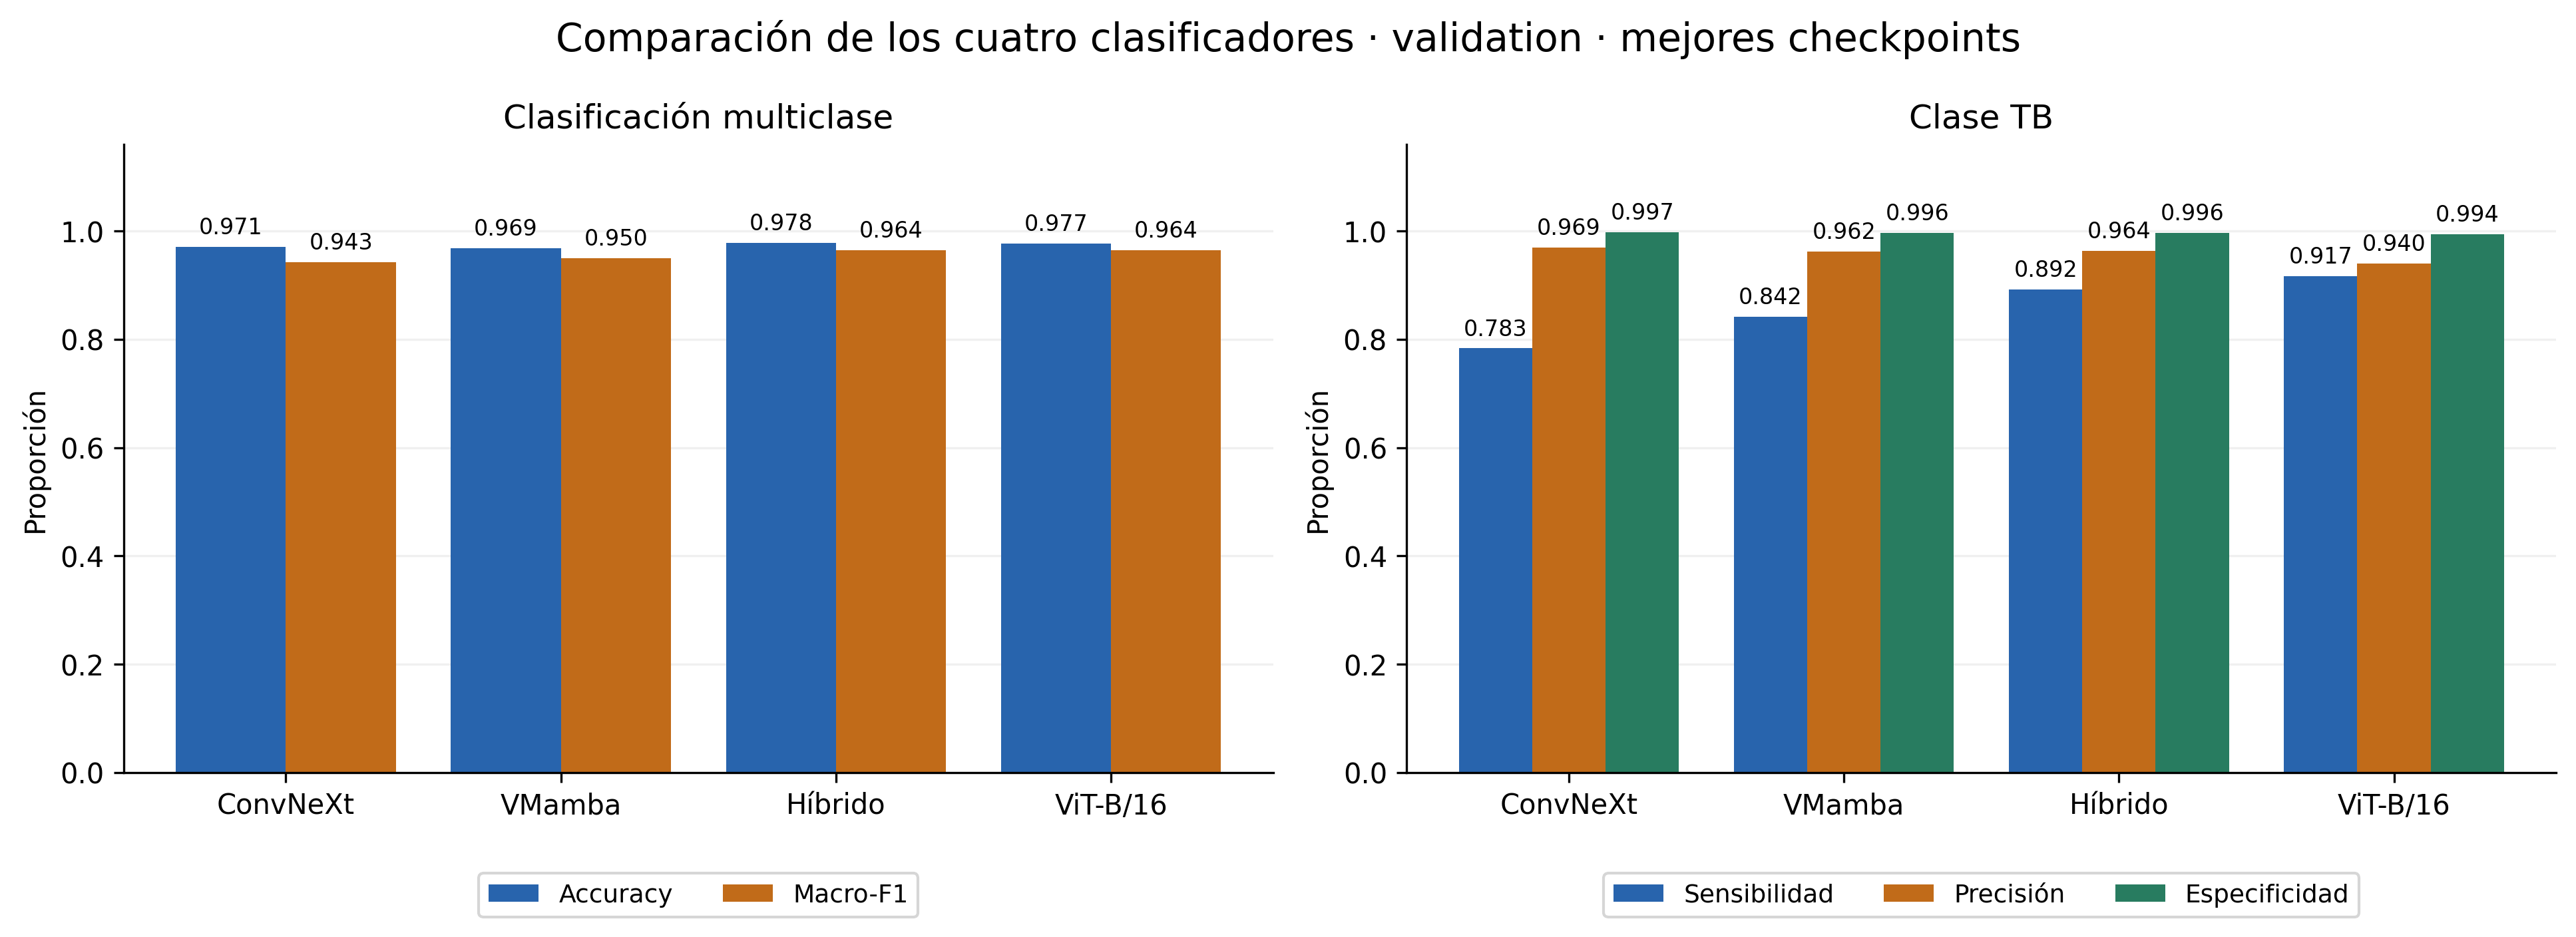

vit_b_16_training.png


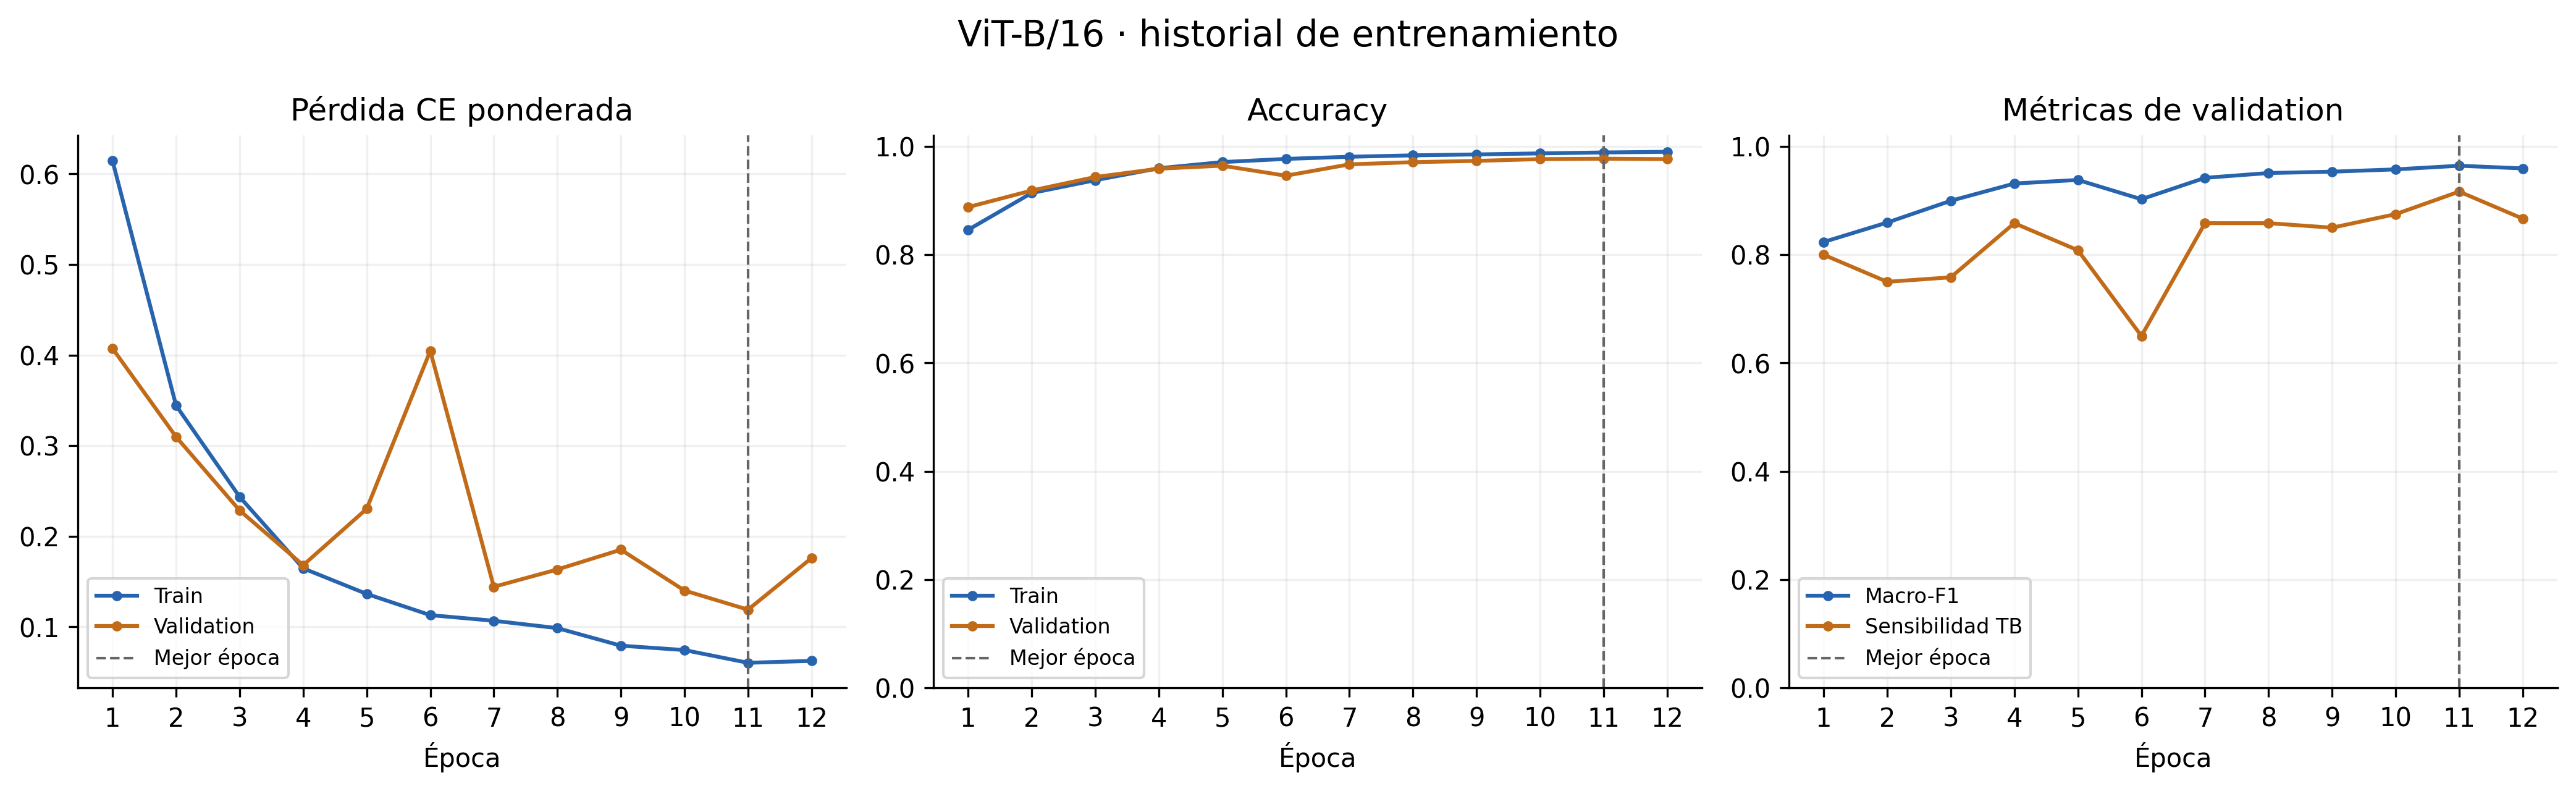

vit_b_16_confusion.png


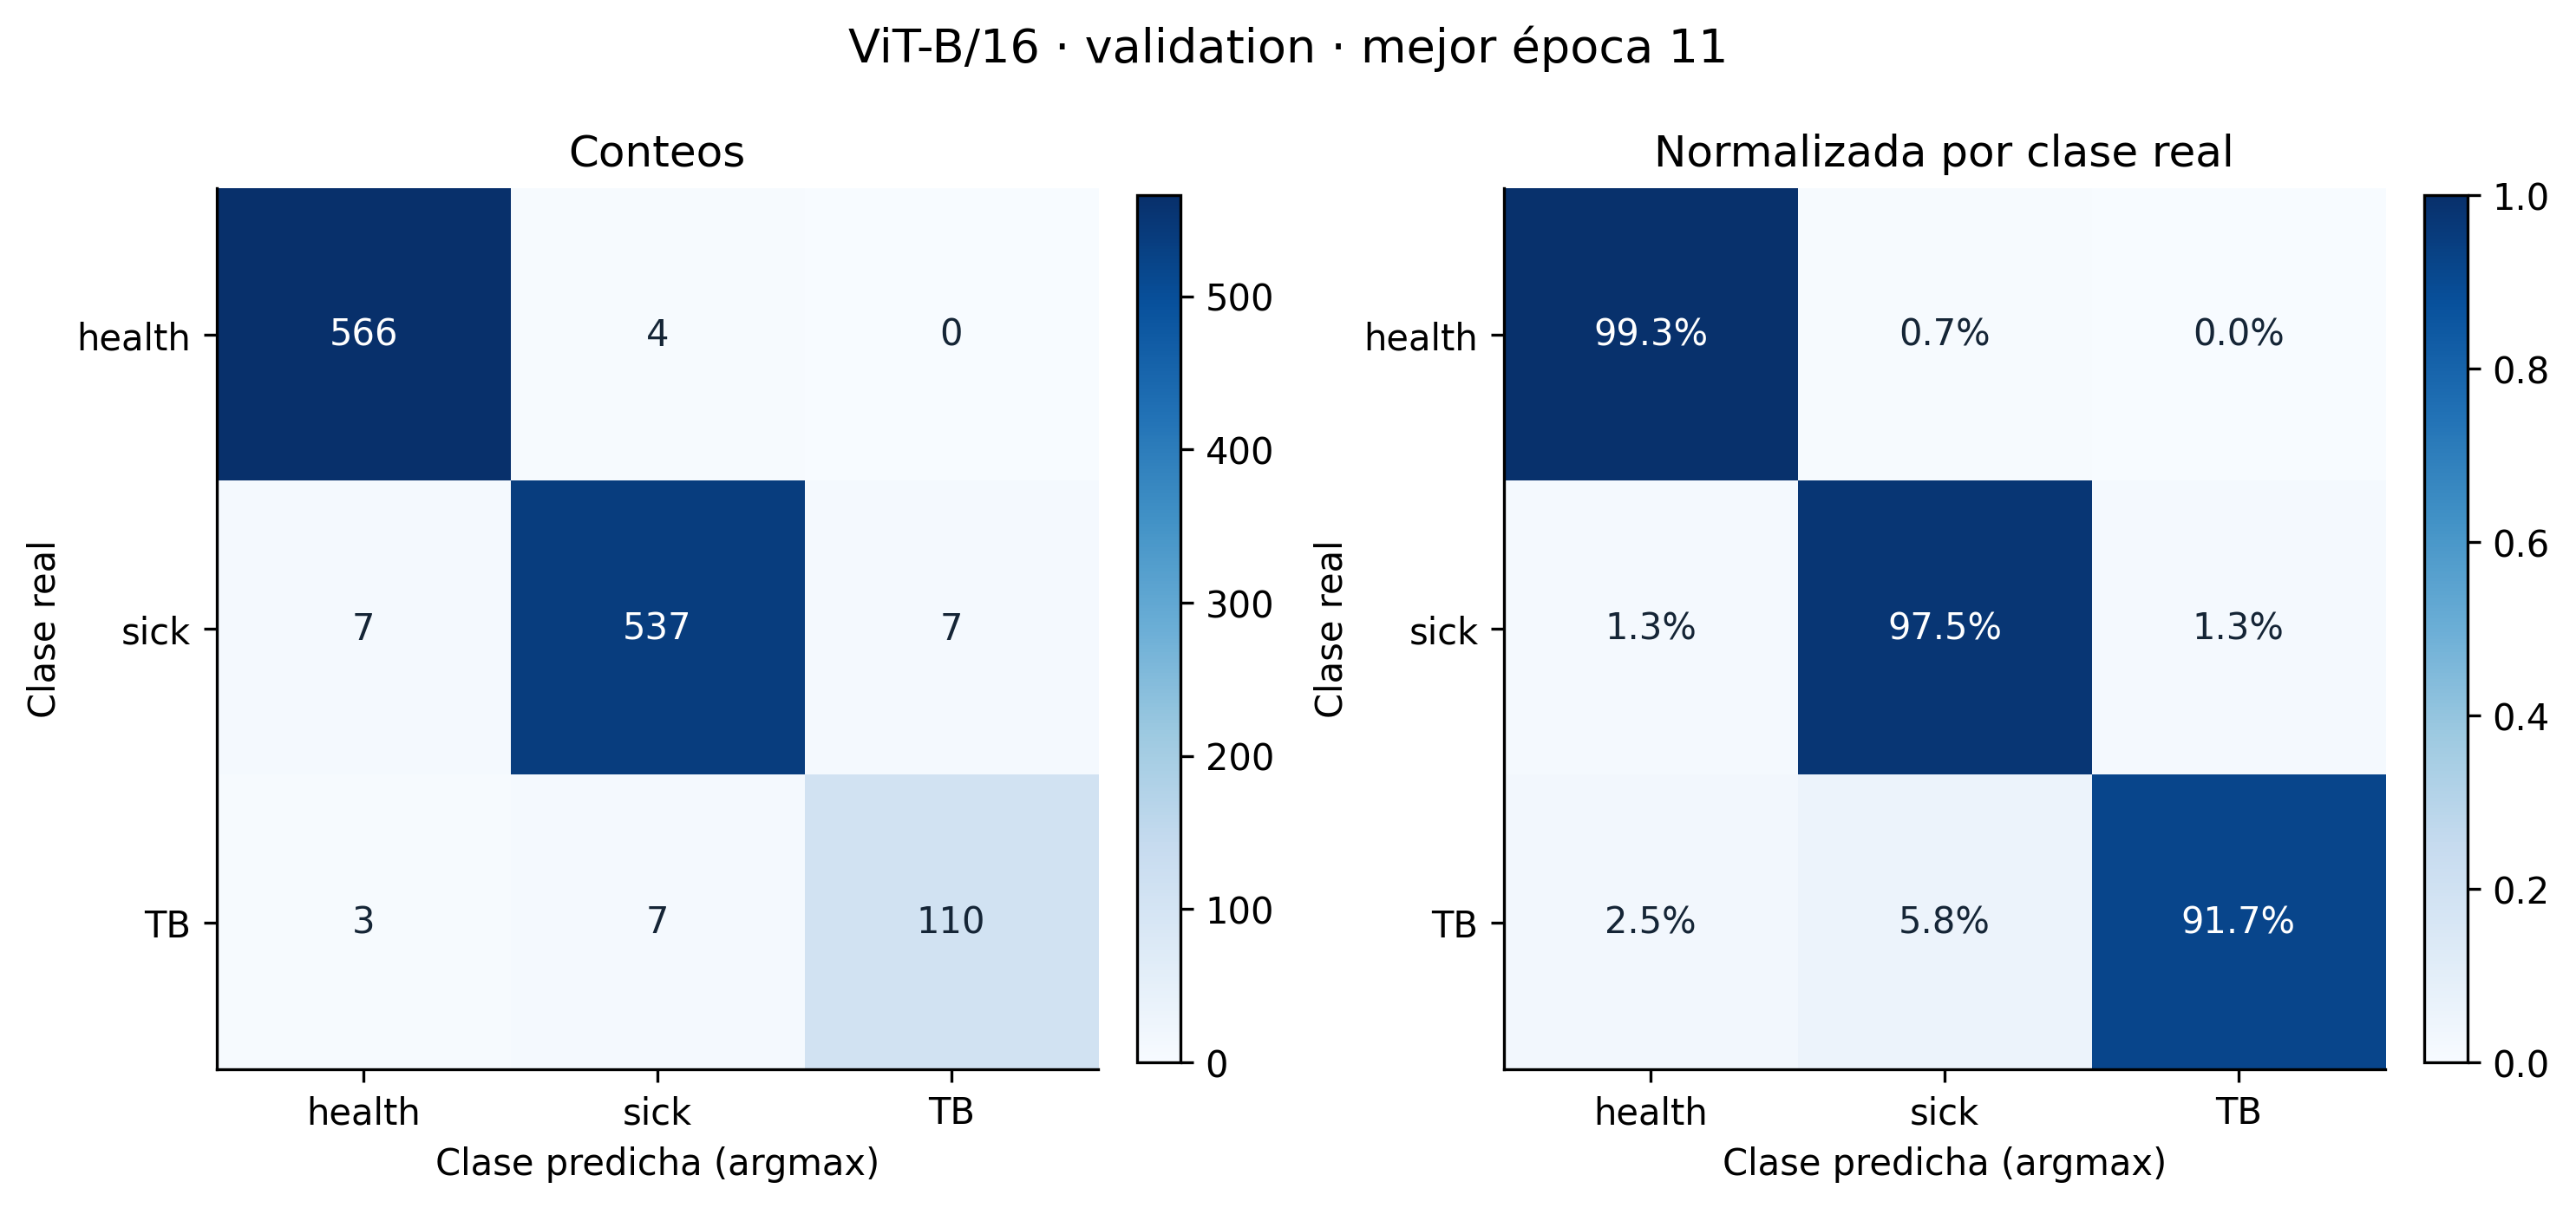

vit_b_16_roc.png


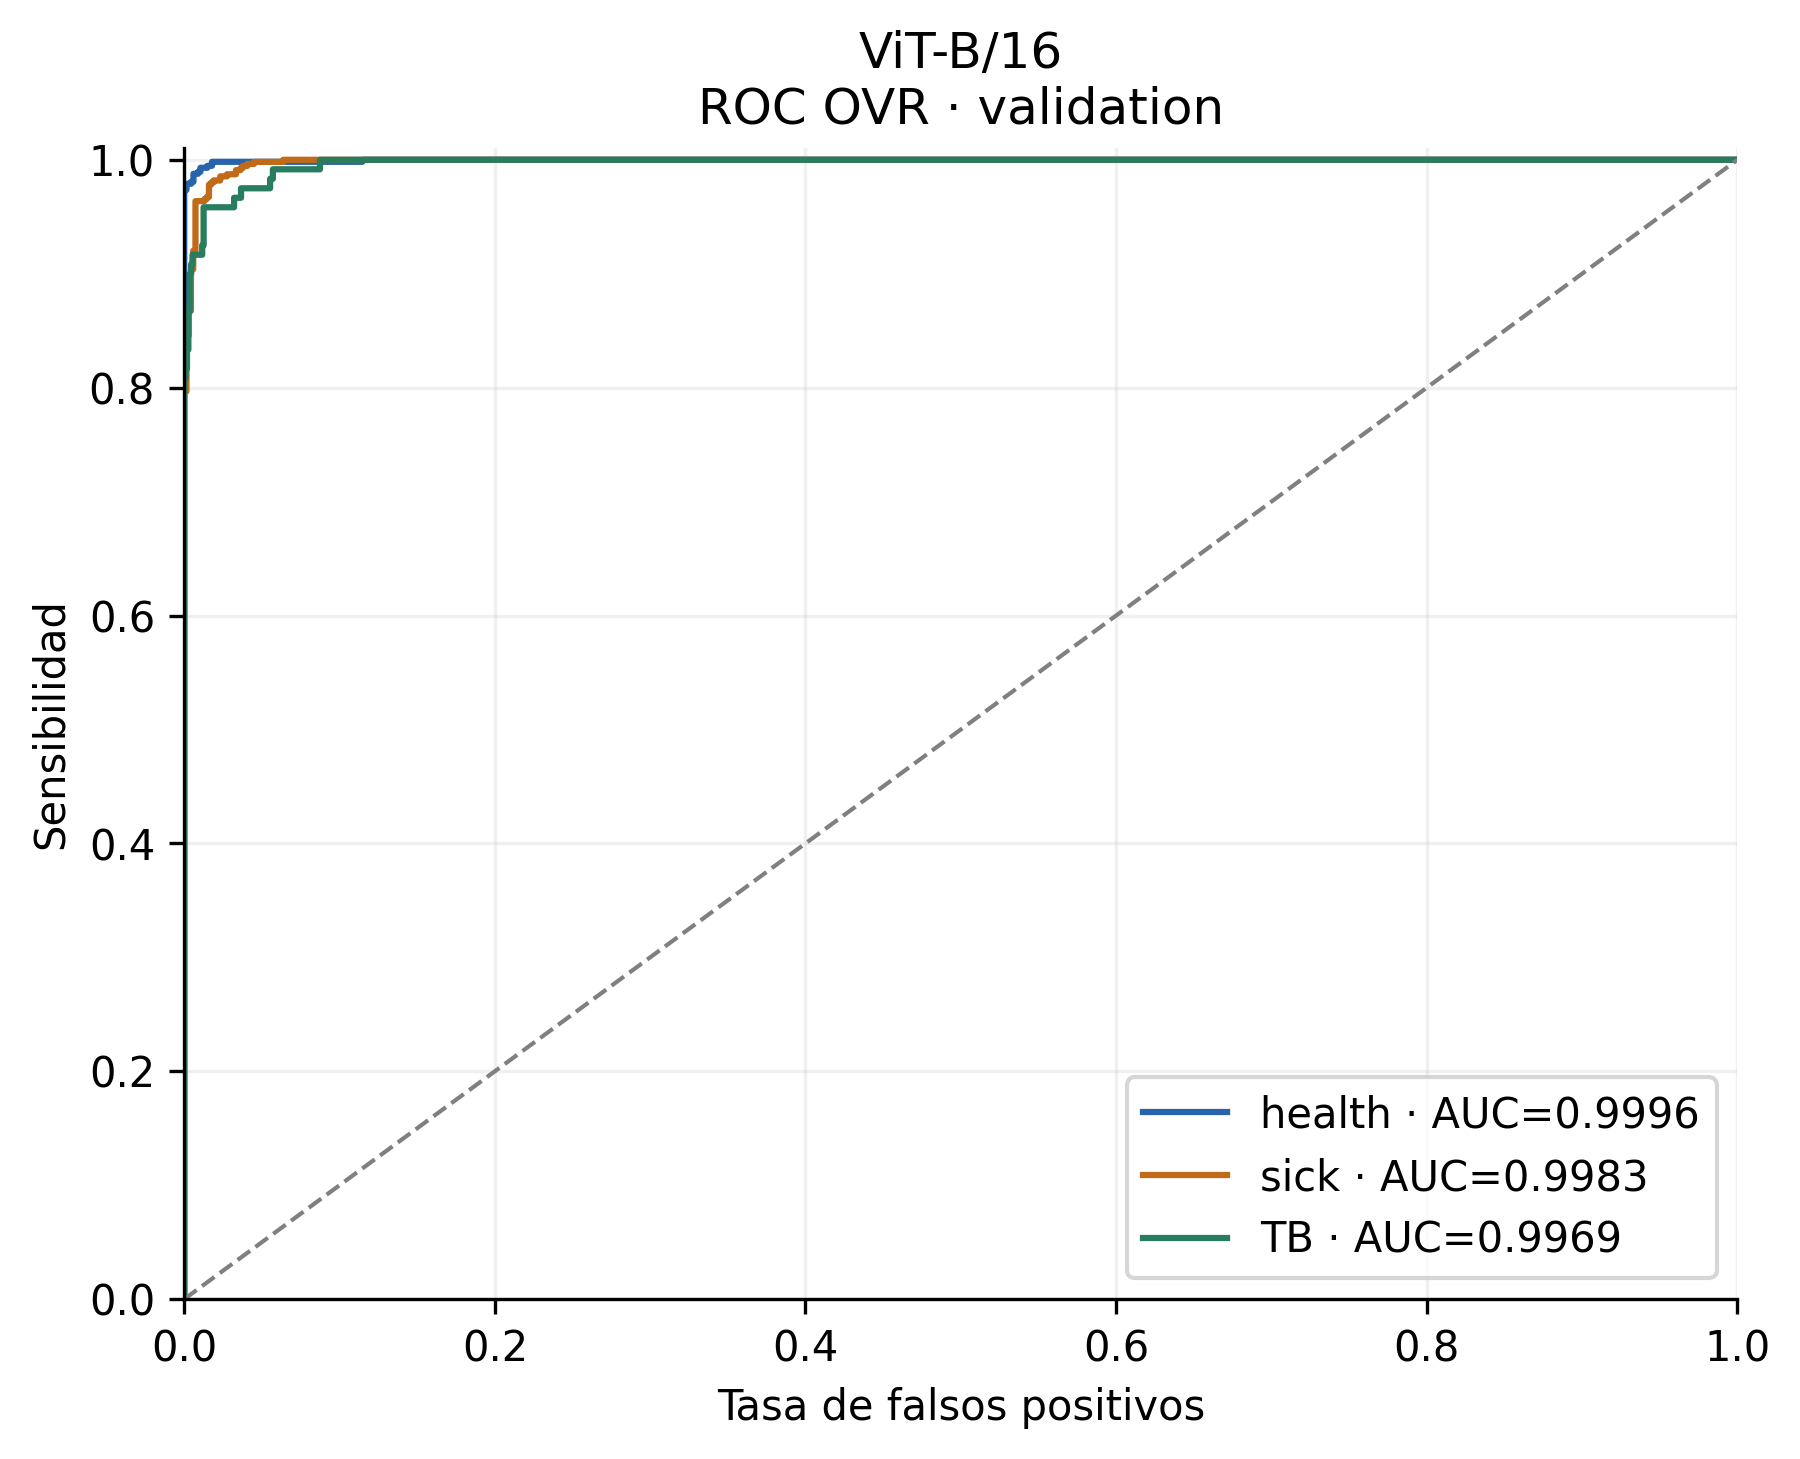

TB_roc_precision_recall.png


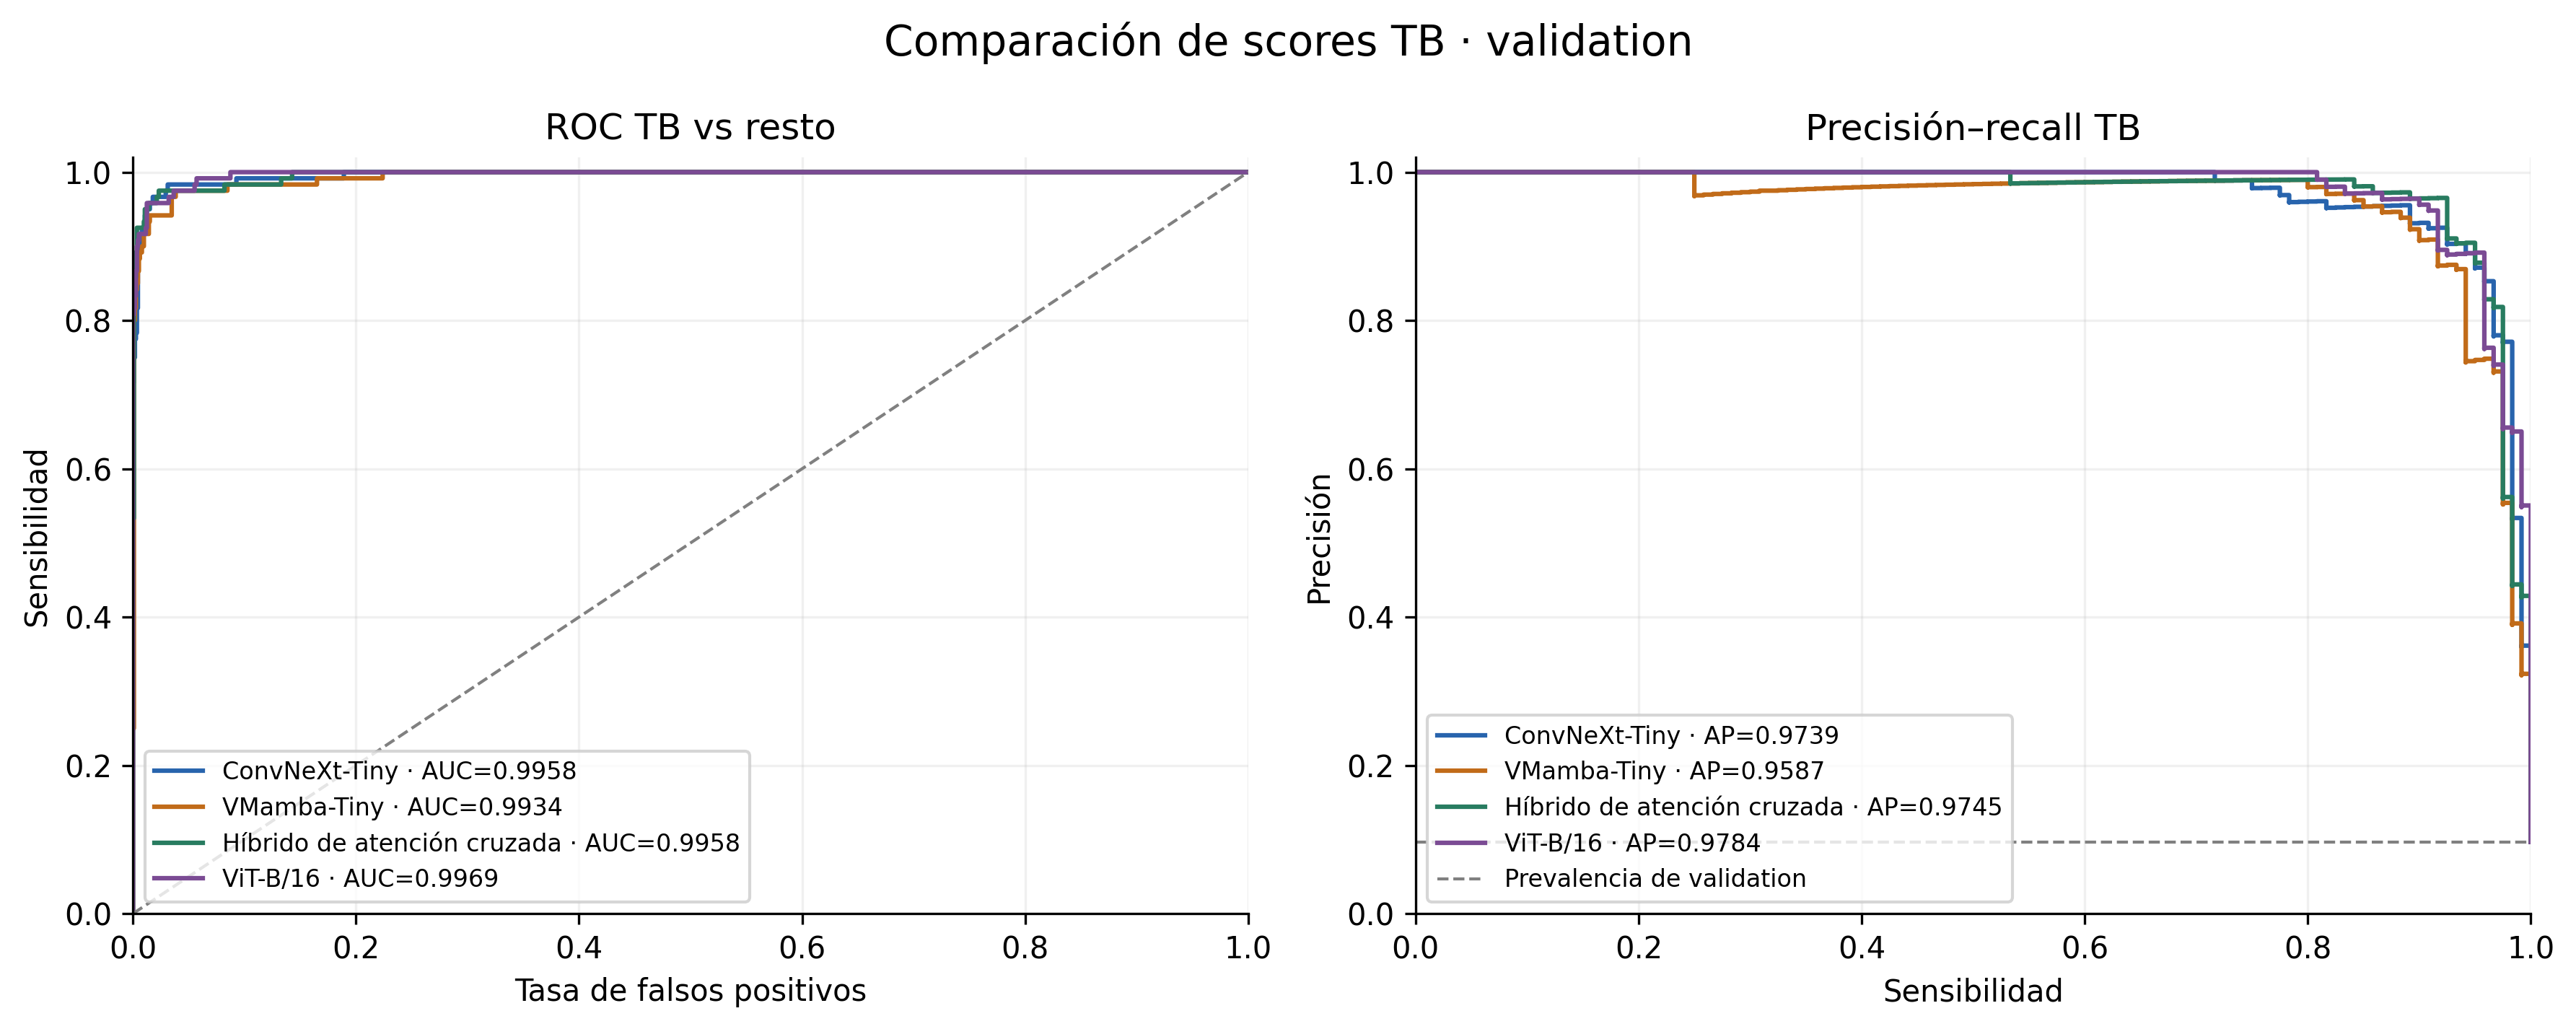

vit_b_16_thresholds.png


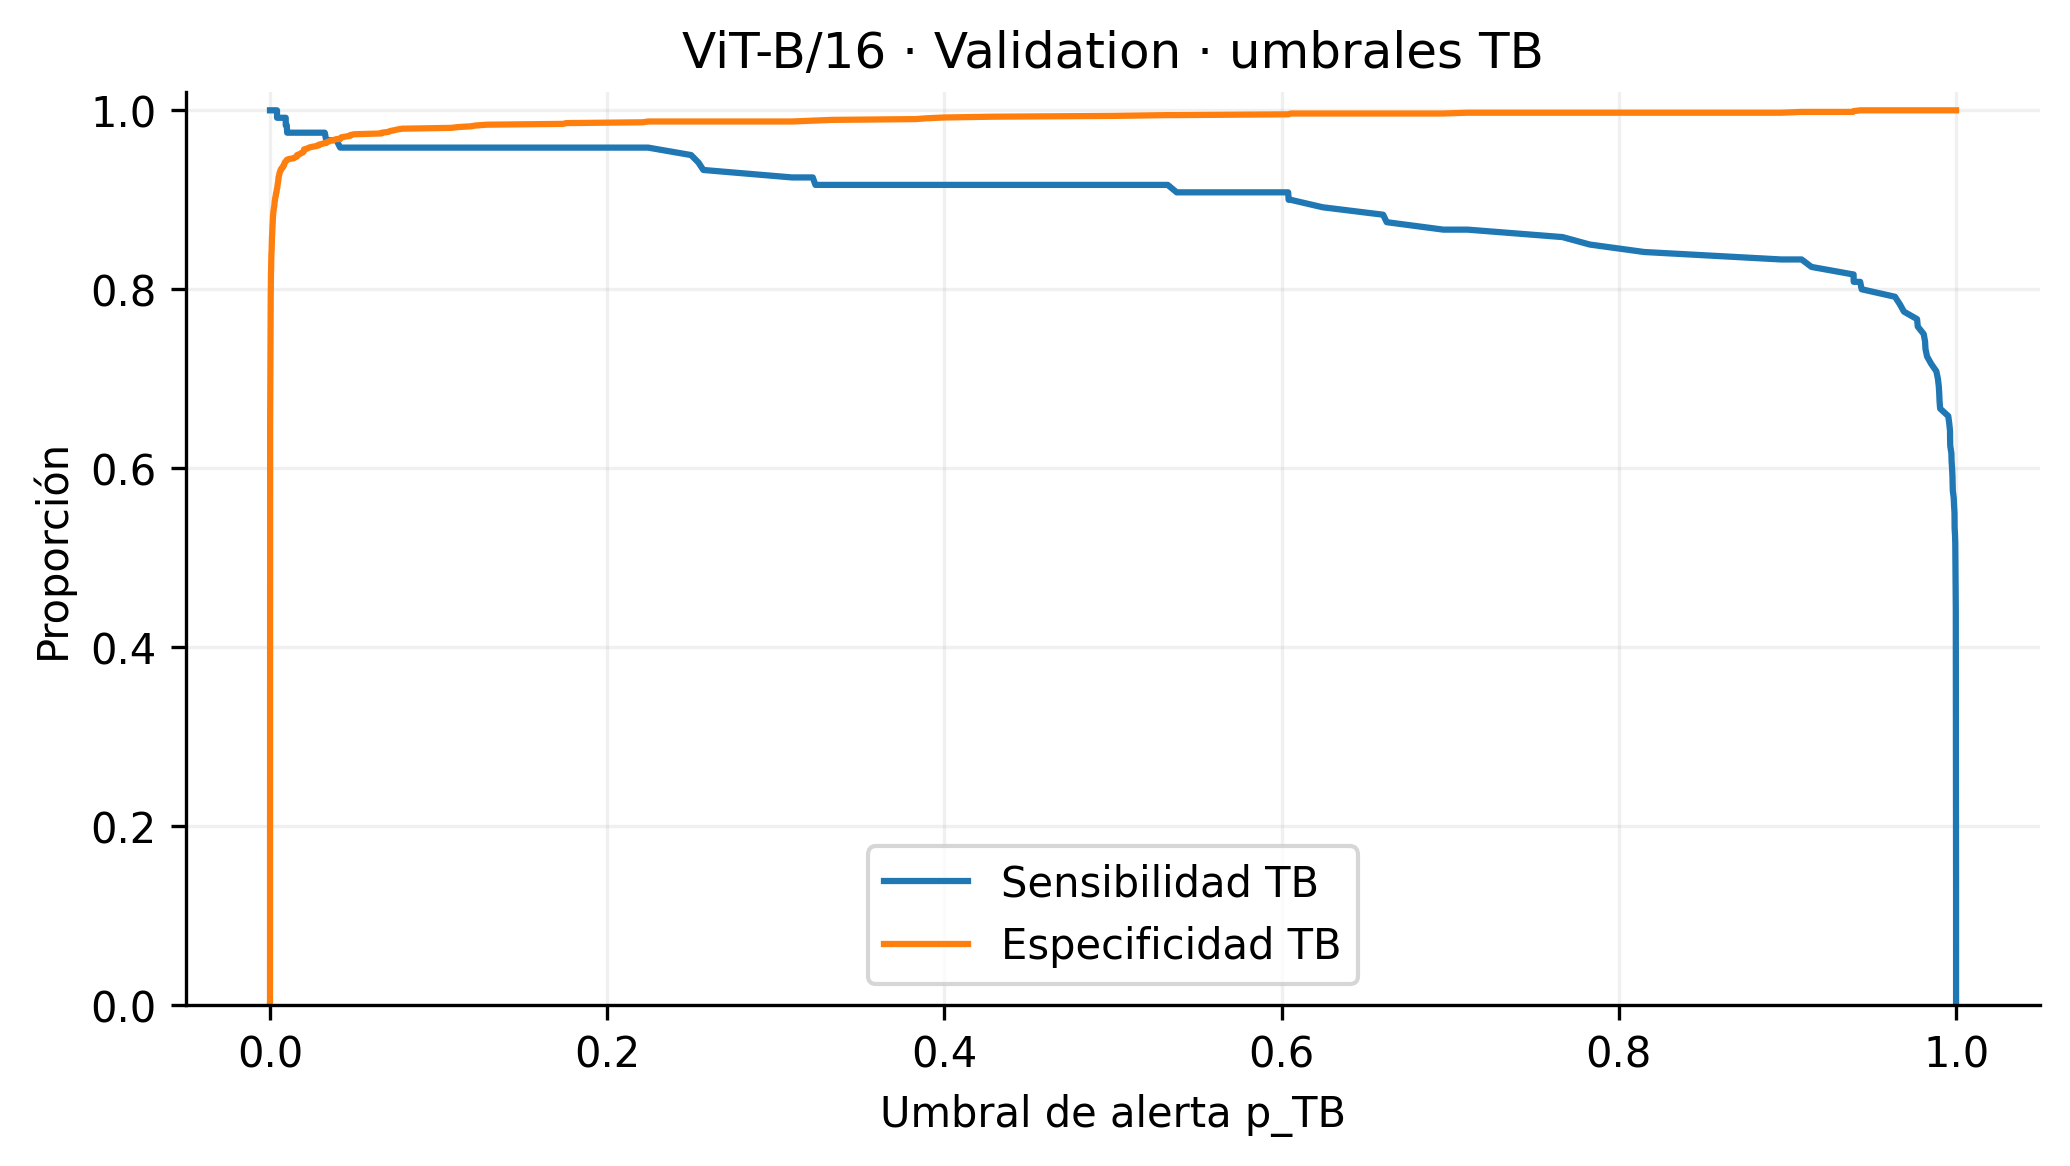

=== PAYLOAD JSON PARA ACTUALIZAR INFORME FASE 5 ===
{
  "schema": "vit_phase5_report_payload_v1",
  "scope": "validation_only",
  "test_evaluated": false,
  "external_evaluated": false,
  "candidate_by_macro_f1": "hybrid_cross_attention",
  "comparison_4models": [
    {
      "architecture": "convnext_tiny",
      "display_name": "ConvNeXt-Tiny",
      "short_label": "ConvNeXt",
      "run_id": "phase3_convnext_tiny_20261103T023002Z_4a7e2a",
      "completed_epochs": 12,
      "best_epoch": 11,
      "stop_reason": "epoch_budget",
      "accuracy": 0.9709911361804996,
      "macro_f1": 0.942715557119158,
      "TB_recall": 0.7833333333333333,
      "TB_precision": 0.9690721649484536,
      "TB_specificity": 0.9973238180196253,
      "TB_roc_auc": 0.9957850133809099,
      "TB_recognized": 94,
      "TB_to_health": 4,
      "TB_to_sick": 22,
      "sick_to_TB": 3,
      "health_to_TB": 0,
      "checkpoint_sha256": "33869c4791569f95c262df2987c9a688649aa4f65c92e51e79f8340c1d0c3616"
    }

In [6]:
import pandas as pd
from datetime import datetime, timezone
from IPython.display import Image, display
from tbxtrain.protocol import atomic_json
from tbxtrain.vit_experiment import export_vit_report_outputs

PRIOR_RUNS = {
    'convnext_tiny': 'phase3_convnext_tiny_20261103T023002Z_4a7e2a',
    'vmamba_tiny': 'phase3_vmamba_tiny_20261103T025536Z_4784e4',
    'hybrid_cross_attention': 'phase3_hybrid_cross_attention_20261103T032205Z_71d127',
}
OUT_EXPORT = DRIVE_BASE / 'results/vit_phase3_export' / (
    VIT_RUN_ID + '_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
)
payload = export_vit_report_outputs(PROJECT_ROOT, DRIVE_BASE, VIT_RUN_ID, OUT_EXPORT, prior_runs=PRIOR_RUNS)
atomic_json(OUT_EXPORT / 'transfer_integrity.json', integrity)

print('=== COMPARACIÓN DE LOS 4 CLASIFICADORES (VALIDATION) ===')
display(pd.DataFrame(payload['comparison_4models'])[
    ['display_name', 'run_id', 'completed_epochs', 'best_epoch', 'stop_reason',
     'accuracy', 'macro_f1', 'TB_recognized', 'TB_recall', 'TB_precision', 'TB_specificity']
])

print('=== HISTORIAL POR ÉPOCA · ViT-B/16 ===')
display(pd.DataFrame(payload['vit_details']['history']))

print('=== TABLA DE UMBRALES TB · ViT-B/16 (VALIDATION) ===')
display(pd.DataFrame(payload['vit_details']['thresholds_grid']))

print('=== TABLA DE UMBRALES TB · CANDIDATO PRINCIPAL POR MACRO-F1 ===', payload['candidate_by_macro_f1'])
display(pd.DataFrame(payload['candidate_thresholds_grid']))

for fig_name in [
    'classifier_comparison.png',
    'vit_b_16_training.png',
    'vit_b_16_confusion.png',
    'vit_b_16_roc.png',
    'TB_roc_precision_recall.png',
    'vit_b_16_thresholds.png',
]:
    print(fig_name)
    display(Image(filename=str(OUT_EXPORT / fig_name), width=1000))

print('=== PAYLOAD JSON PARA ACTUALIZAR INFORME FASE 5 ===')
print(json.dumps(payload, indent=2, ensure_ascii=False))
print('Carpeta exportada en Drive:', OUT_EXPORT)
print('Guarde este notebook ejecutado con Ctrl+S y envíe el .ipynb (y/o esta carpeta de Drive).')